In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
image_path = "images/00_image.jpg"

image = cv2.imread(image_path)
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("Min pixel:", image.min())
print("Max pixel:", image.max())

Shape: (2400, 1320, 3)
Dtype: uint8
Min pixel: 0
Max pixel: 255


In [3]:
def show_images(images, titles, figsize=(16, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)

    if len(images) == 1:
        axes = [axes]

    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

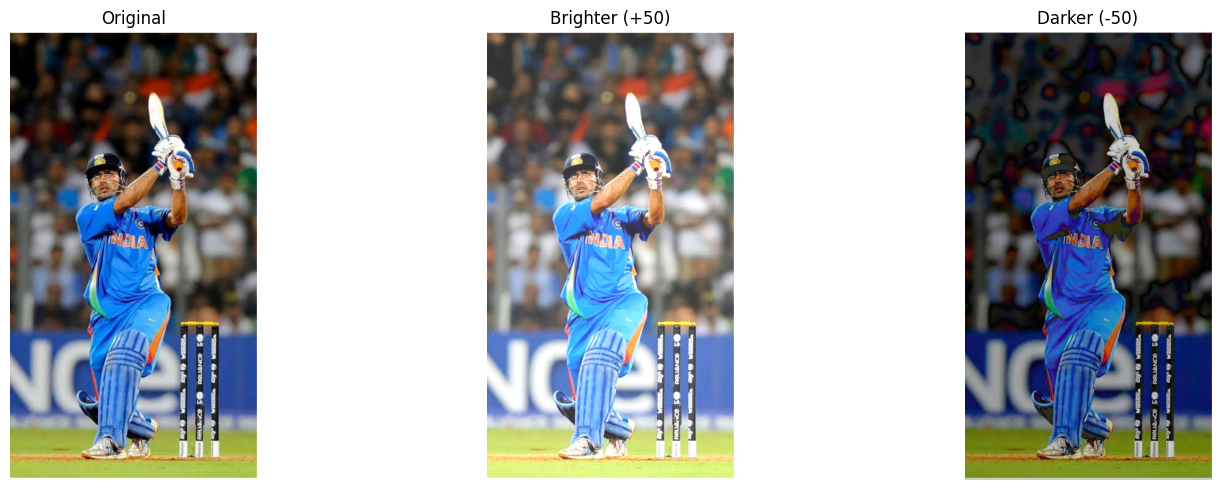

In [4]:
brightness_up = cv2.convertScaleAbs(image, alpha=1.0, beta=50)
brightness_down = cv2.convertScaleAbs(image, alpha=1.0, beta=-50)

show_images(
    [image, brightness_up, brightness_down],
    ["Original", "Brighter (+50)", "Darker (-50)"]
)

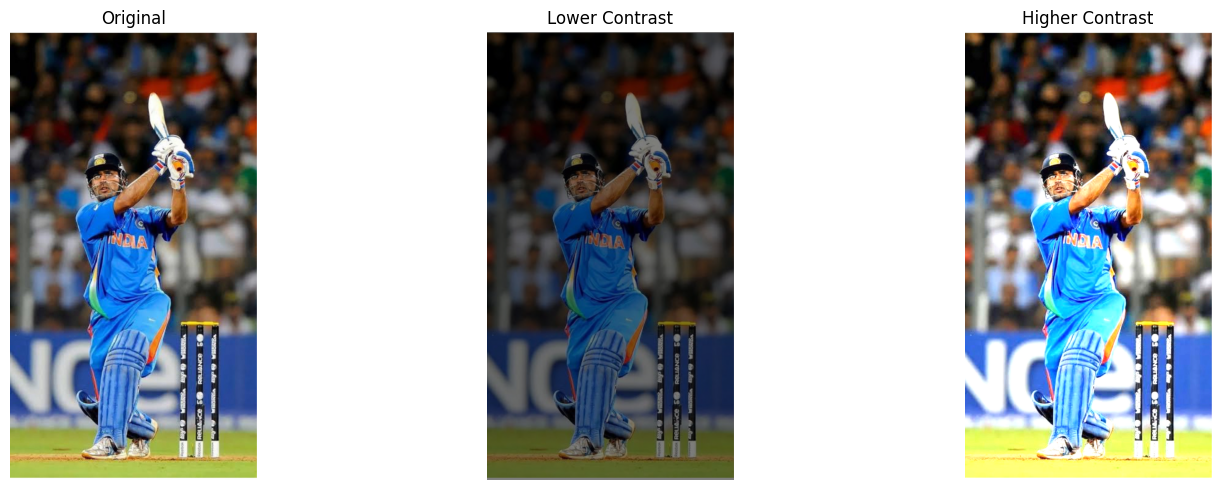

In [5]:
low_contrast = cv2.convertScaleAbs(image, alpha=0.5, beta=0)
high_contrast = cv2.convertScaleAbs(image, alpha=1.5, beta=0)

show_images(
    [image, low_contrast, high_contrast],
    ["Original", "Lower Contrast", "Higher Contrast"]
)

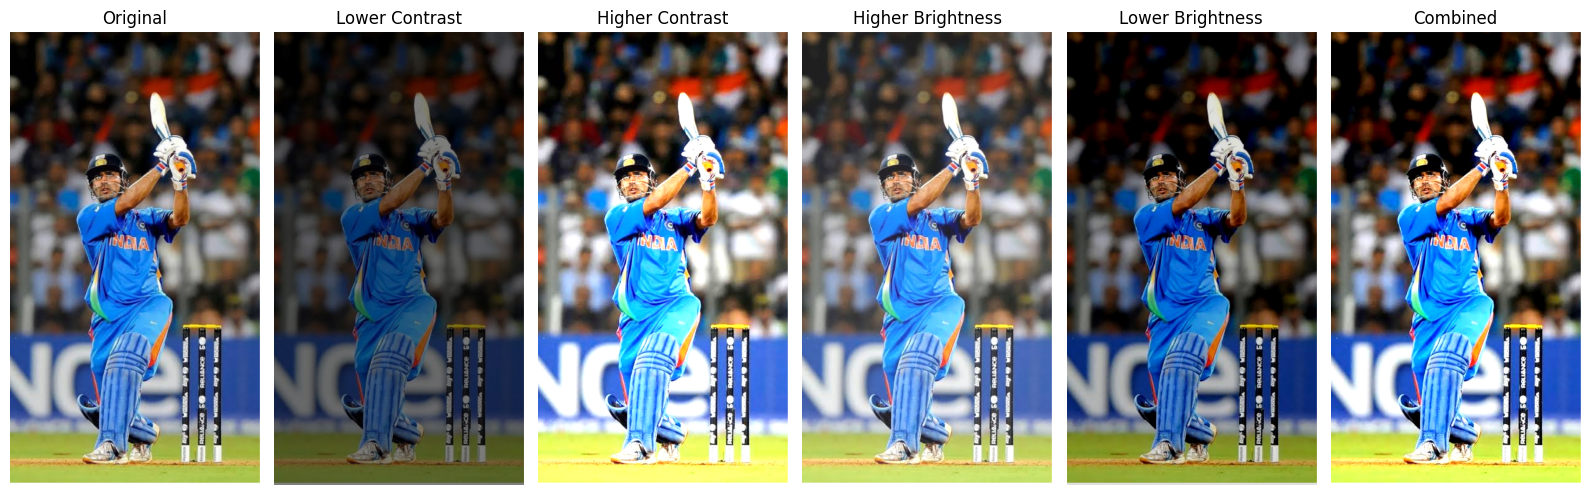

In [6]:
def adjust_intensity(image, alpha=1.0, beta=0):
    result = image.astype(np.float32) * alpha + beta
    return np.clip(result, 0, 255).astype(np.uint8)

contrast_up = adjust_intensity(image, alpha=1.5)
contrast_down = adjust_intensity(image, alpha=0.5)
brightness_up = adjust_intensity(image,beta=30)
brightness_down = adjust_intensity(image,beta=-30)

combined_effect = adjust_intensity(image,alpha=1.5,beta=-30)

show_images(
    [image, contrast_down, contrast_up,brightness_up,brightness_down,combined_effect],
    ["Original", "Lower Contrast", "Higher Contrast","Higher Brightness","Lower Brightness","Combined"]
)

In [7]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

print("Original grayscale min:", gray.min())
print("Original grayscale max:", gray.max())
print("Original grayscale range:", gray.max() - gray.min())

Original grayscale min: 0
Original grayscale max: 255
Original grayscale range: 255


In [8]:
gray_float = gray.astype(np.float32)

gray_min = gray_float.min()
gray_max = gray_float.max()

if gray_max > gray_min:
    stretched = (
        (gray_float - gray_min)
        / (gray_max - gray_min)
        * 255
    ).astype(np.uint8)
else:
    stretched = gray.copy()

print("Stretched min:", stretched.min())
print("Stretched max:", stretched.max())

Stretched min: 0
Stretched max: 255


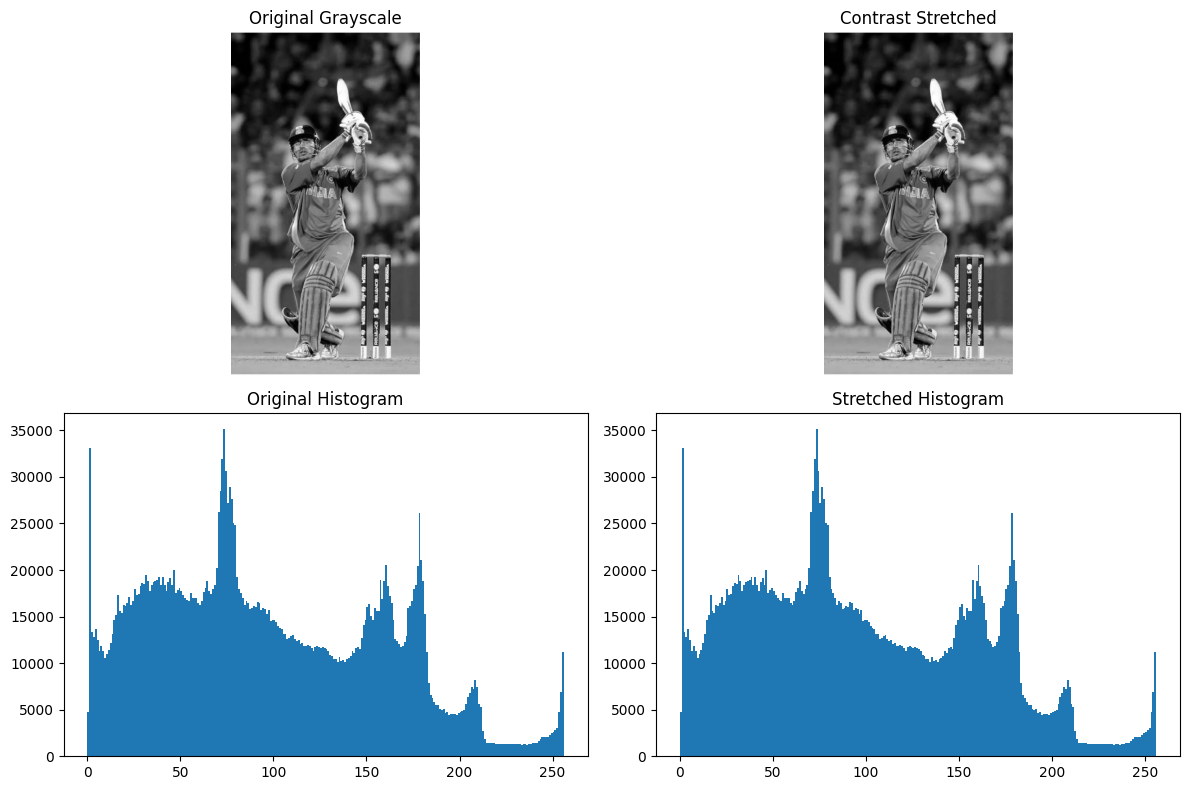

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Grayscale")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(stretched.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Stretched Histogram")

for ax in axes.flat:
    if ax.images:
        ax.axis("off")

plt.tight_layout()
plt.show()

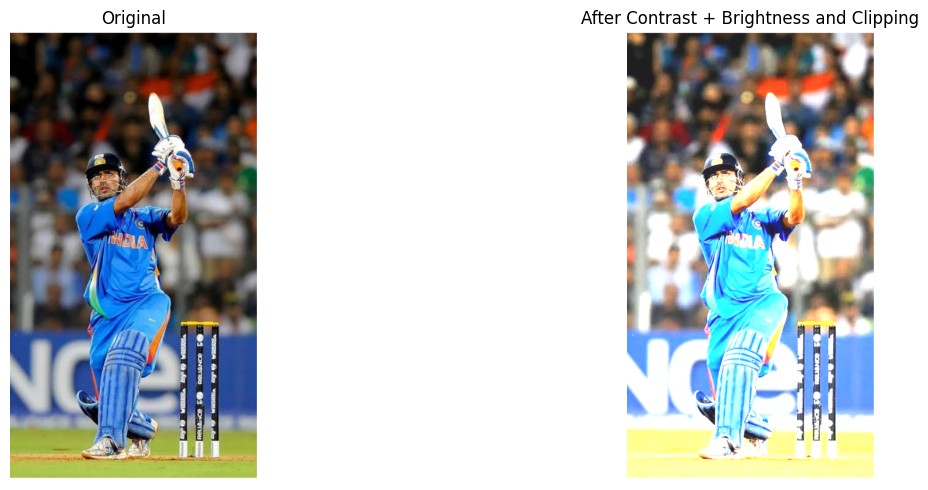

In [10]:
bright_float = image.astype(np.float32) * 1.8 + 30

clipped = np.clip(bright_float, 0, 255).astype(np.uint8)

show_images(
    [image, clipped],
    ["Original", "After Contrast + Brightness and Clipping"]
)

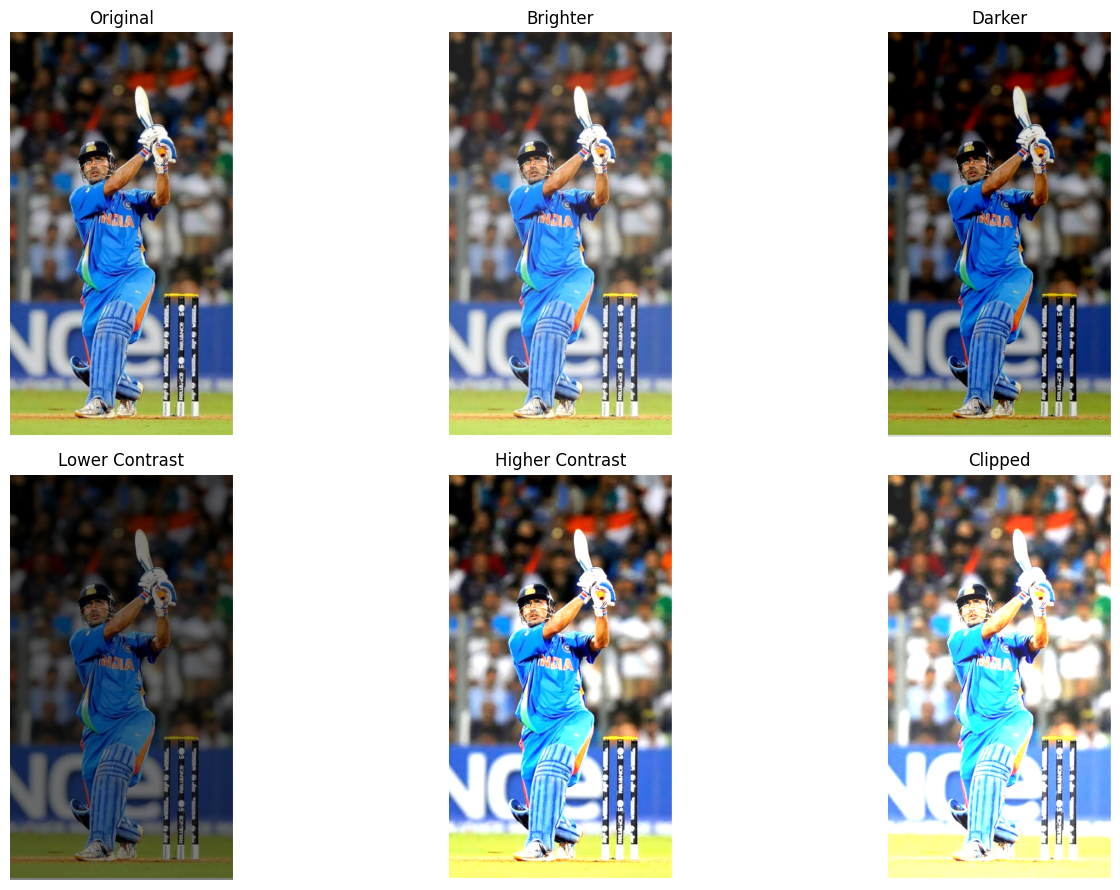

In [12]:
results = [
    image,
    brightness_up,
    brightness_down,
    contrast_down,
    contrast_up,
    clipped
]

titles = [
    "Original",
    "Brighter",
    "Darker",
    "Lower Contrast",
    "Higher Contrast",
    "Clipped"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, img, title in zip(axes.flat, results, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig(r"images\1.Intesity Operations.jpg", dpi=300, bbox_inches="tight")
plt.show()